## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [9]:
import pickle

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()
print(token_freq[:10])

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

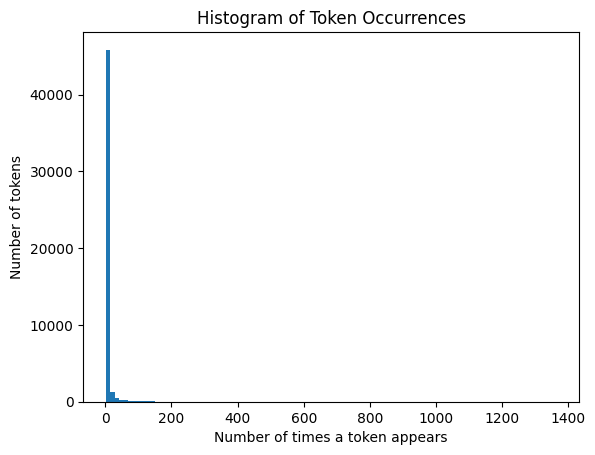

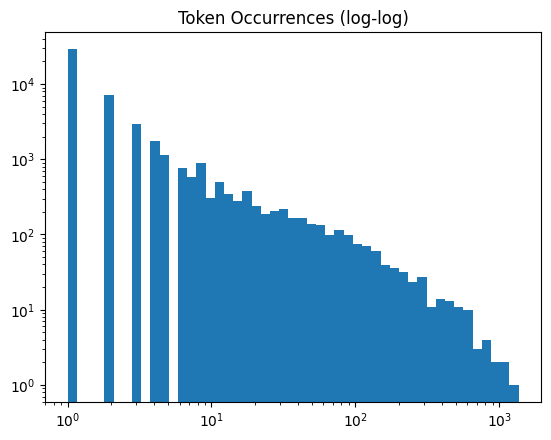

In [10]:
import matplotlib.pyplot as plt
import numpy as np

counts = np.array([freq for token, freq in token_freq])

plt.hist(counts, bins=100)
plt.title('Histogram of Token Occurrences')
plt.xlabel('Number of times a token appears')
plt.ylabel('Number of tokens')
plt.show()

#crazy right skew so I'll do logarithmic

plt.hist(counts, bins=np.logspace(0, np.log10(counts.max()), 50))
plt.xscale('log'); plt.yscale('log')
plt.title('Token Occurrences (log-log)')
plt.show()

The frequencies are very uneven. A small number of tokens appear very often, while most tokens appear only once or a handful of times. The histogram is heavily right-skewed. There's one tall spike near zero, made up of all the rare words, and then a long, thin tail stretching to the right for the few very common words. On a log scale the pattern looks like a roughly straight downward line, which is typical of natural language (Zipf's law).

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Load data
df = pd.read_parquet('/content/Phishing_clean.parquet')
df.head()

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [12]:
# 1. 80/20 train-test split
y = df['Email Type']
X = df.drop(columns='Email Type')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=125)

In [13]:
# 2. Linear regression and R^2
model = LinearRegression()
model.fit(X_train, y_train)

print('Train R^2:', model.score(X_train, y_train))
print('Test R^2:', model.score(X_test, y_test))

Train R^2: 0.7659684115003009
Test R^2: 0.6701758721312419


The training R^2 is about 0.77 and the test R^2 is about 0.67. The model explains a good share of the variation in whether an email is a scam. It does better on the training data than on the test data, which suggests some overfitting. That makes sense, since the model has thousands of word features and can pick up patterns specific to the training emails that don't carry over to new ones.

In [14]:
# 3. largest coefficients in absolute value
coefs = pd.DataFrame({'token': X.columns, 'coef': model.coef_})
coefs['abs_coef'] = coefs['coef'].abs()
coefs.sort_values('abs_coef', ascending=False).head(20)

,token,coef,abs_coef
1504,background-image:,-1.201203,1.201203
740,localized,0.815112,0.815112
906,aging,0.735023,0.735023
2362,thermal,0.590412,0.590412
1406,"helvetica,",0.587472,0.587472
835,intervention,-0.580474,0.580474
1302,erectile,0.575784,0.575784
1511,burning,-0.569225,0.569225
1839,form.,0.560255,0.560255
2559,april's,-0.525984,0.525984


The words with the biggest coefficients are mostly rare or unusual tokens, not everyday words. Words like "erectile," "xanaax," "girlfriend," "aging," and "localized" push predictions toward scam, which fits common spam topics like drug ads and dating offers. Words like "cnet," "zdnet," "intervention," and "background-image:" push predictions toward legitimate, since they mostly come from newsletters and tech news emails. Since many of these words only show up in a few emails, they have a strong effect when they appear but don't matter for most emails.

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

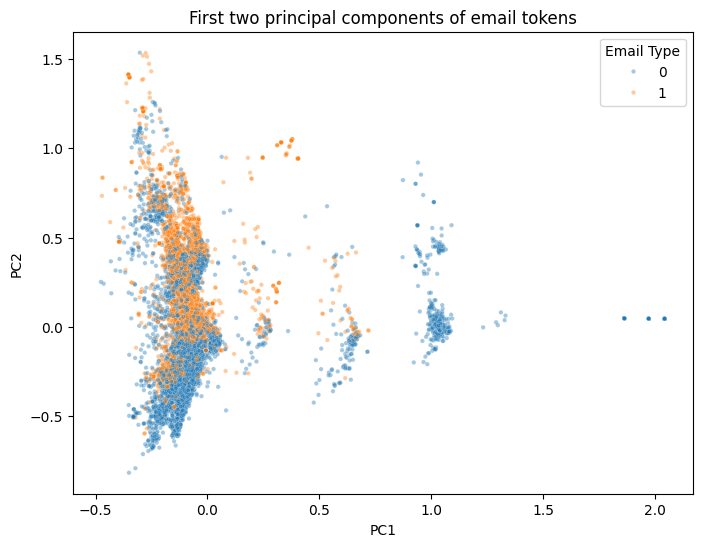

In [19]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

#token matrix without the outcome variable
X = df.drop(columns='Email Type')
y = df['Email Type']

# PCA with two components
pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

# put the components in a DataFrame for plotting
pca_df = pd.DataFrame(pcs, columns=['PC1', 'PC2'])
pca_df['Email Type'] = y.values

# Scatter plot colored by phishing or not
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Email Type', alpha=0.4, s=10)
plt.title('First two principal components of email tokens')
plt.show()

Most emails are bunched together in one big cluster on the left side of the plot, and scam and legitimate emails overlap a lot there. Scams lean slightly higher on PC2 and legitimate emails slightly lower, but there's no clear line between them. There are also a few small, separate clusters to the right. They're mostly legitimate emails and are probably groups of very similar messages, like newsletters. Overall, the first two components dont separate scams from legitimate emails very well. They capture only a small share of the information in the data, and PCA doesn't use the scam labels when it finds them.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [20]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

#fit PCA on the training data only, then apply it to both sets
pca = PCA(n_components=2610)
Z_train = pca.fit_transform(X_train)
Z_test = pca.transform(X_test)

#regression on the principal components
pc_model = LinearRegression()
pc_model.fit(Z_train, y_train)

print('Train R^2:', pc_model.score(Z_train, y_train))
print('Test R^2:', pc_model.score(Z_test, y_test))

Train R^2: 0.7650509639569709
Test R^2: 0.6718439815209292


The training R^2 is about 0.77 and the test R^2 is about 0.67. That's basically the same as the regular linear regression. The results match because 2,610 components keep almost all of the information from the original word columns. The model is working with nearly the same information, just organized differently, so its predictions barely change.

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

Principal components are uncorrelated with each other, while the original word columns often overlap. For example, words that tend to show up together in the same kinds of emails are correlated and that can make the regression coefficients unstable and hard to trust. With principal components each one carries separate information, so the regression is more stable. Also, PCA sorts the components from most to least important, based on how much variation each one captures. That lets you keep only the top components and drop the rest, which are mostly noise. With fewer features, the model is simpler, faster to fit, and less likely to overfit the training data. Essentially in this scenario the advantage isn't a higher R^2 at 2,610, it's that PCA lets you shrink the model a lot while keep almost the same performance.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Grady Berlik

**Date:** 10/21/2026

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [17]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]